# 03 — Experimentos opcionais com a rede neural

Este notebook reúne os estudos retirados do notebook 02. Use o kernel **`.venv`**, reinicie-o e execute **todas as células na ordem**. Não precisa executar o notebook 02 antes: as matrizes são carregadas diretamente de `Modelos/dados_ml.joblib`.

**Pré-requisitos:** preparação dos dados concluída, `Dados/pedidos_ml.csv`, consolidado e geolocalização original disponíveis. Não precisa de PostgreSQL nem API de GenAI.

**Estudos:** CrossEntropy → constantes/categorias raras → repetição com três sementes → diagnósticos de erros → PCA → coordenadas → diferenças temporais e auditoria da coorte. São 16 treinos de redes no total; esta execução demora mais que a do notebook principal.

As redes destes estudos têm **duas saídas e CrossEntropyLoss ponderada**. “Original” nas tabelas significa a versão CrossEntropy com todos os atributos, não a rede BCE de uma saída da aplicação. Compare versões dentro do mesmo protocolo. Mantemos a fila de 10%, até 150 épocas, paciência 50 e seleção pelo número de atrasos encontrados na validação.

As transformações são ajustadas somente no treino. O conjunto de teste não é avaliado aqui. Os recortes de erro são exploratórios e não demonstram causas dos atrasos. Nenhum modelo, CSV ou tabela PostgreSQL é sobrescrito; os resultados ficam nas saídas deste notebook.

**Sobre as saídas salvas:** execução integral conferida em 13/11/2026, em cópia isolada com dados reais e 16 treinos completos. Os resultados não foram adotados automaticamente pela aplicação.


## 1. Preparação independente

In [1]:
from pathlib import Path

import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

raiz = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "src/tratar_dados_ml.py").is_file())

if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.tratar_dados_ml import localizar_entrada

# O nome antigo é aceito apenas se o consolidado atual não existir.
caminho_consolidado = localizar_entrada()

dados = joblib.load(raiz / "Modelos" / "dados_ml.joblib")

X_treino = dados["X"]["treino"]
y_treino = dados["y"]["treino"]

X_validacao = dados["X"]["validacao"]
y_validacao = dados["y"]["validacao"]

print("Treino:", X_treino.shape, y_treino.shape)
print("Validação:", X_validacao.shape, y_validacao.shape)

assert X_treino.shape[1] == X_validacao.shape[1]
for particao in ["treino", "validacao", "teste"]:
    ids_particao = dados["metadados"][particao]["order_id"]
    assert ids_particao.is_unique
    assert len(ids_particao) == len(dados["X"][particao]) == len(dados["y"][particao])
    assert set(np.unique(dados["y"][particao])) == {0, 1}

print("Consolidado:", caminho_consolidado.name)
print("Cortes temporais:", dados["cortes"])
print("Kernel:", sys.executable)


Treino: (41173, 159) (41173,)
Validação: (24667, 159) (24667,)
Consolidado: pedidos_consolidados_teste.csv
Cortes temporais: {'validacao': '2018-01-01 00:00:00', 'teste': '2018-05-01 00:00:00'}
Kernel: C:\Users\ghost\OneDrive\Documentos\ChatGPT\Nikolas\BootcampTCS\EntregaCertaAI\.venv\Scripts\python.exe


## 2. CrossEntropy com duas saídas

Este estudo não substitui automaticamente a BCE do notebook principal.

Época 001 | Perda treino: 0.6576 | Perda validação: 0.6945 | AP: 0.1656 | Atrasos na fila: 457


Época 002 | Perda treino: 0.6250 | Perda validação: 0.6981 | AP: 0.1885 | Atrasos na fila: 555


Época 003 | Perda treino: 0.6133 | Perda validação: 0.6877 | AP: 0.1960 | Atrasos na fila: 580


Época 004 | Perda treino: 0.6053 | Perda validação: 0.6421 | AP: 0.2004 | Atrasos na fila: 596


Época 005 | Perda treino: 0.5964 | Perda validação: 0.6628 | AP: 0.1905 | Atrasos na fila: 554


Época 006 | Perda treino: 0.5892 | Perda validação: 0.6562 | AP: 0.1892 | Atrasos na fila: 555


... (44 outputs left out)

Época 051 | Perda treino: 0.3923 | Perda validação: 1.0941 | AP: 0.1296 | Atrasos na fila: 374


Época 052 | Perda treino: 0.3862 | Perda validação: 1.0409 | AP: 0.1271 | Atrasos na fila: 345


Época 053 | Perda treino: 0.3896 | Perda validação: 1.1447 | AP: 0.1300 | Atrasos na fila: 363


Época 054 | Perda treino: 0.3901 | Perda validação: 1.0617 | AP: 0.1276 | Atrasos na fila: 355
Parada antecipada.

Melhor época: 4
Atrasos encontrados: 596 em 2466
Precision: 24.17%
Recall: 23.90%
F1: 24.03%
AP: 0.2004
Matriz de confusão:
[[20303  1870]
 [ 1898   596]]


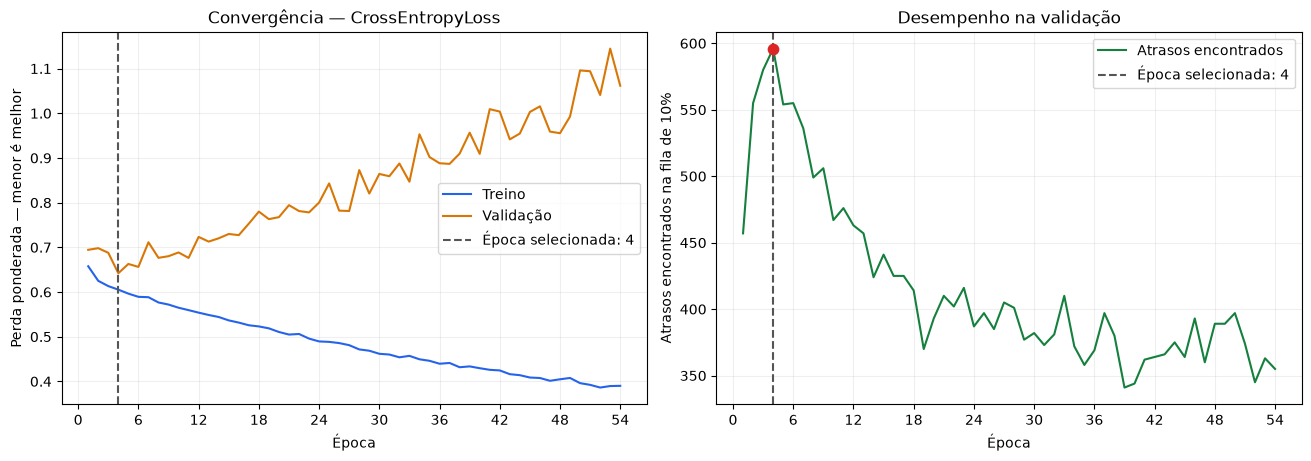

In [2]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from copy import deepcopy
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, confusion_matrix
)

# Configurações.
SEMENTE_CE = 7
EPOCAS_CE = 150
PACIENCIA_CE = 50
torch.manual_seed(SEMENTE_CE)

# Dados: somente treino e validação.
X_treino_ce = torch.tensor(np.asarray(X_treino), dtype=torch.float32)
y_treino_ce = torch.tensor(np.asarray(y_treino).ravel(), dtype=torch.long)
X_validacao_ce = torch.tensor(np.asarray(X_validacao), dtype=torch.float32)
y_validacao_ce = np.asarray(y_validacao).ravel().astype(int)
y_validacao_tensor_ce = torch.tensor(y_validacao_ce, dtype=torch.long)

# Rede nova, separada do modelo da aplicação.
modelo_ce = nn.Sequential(
    nn.Linear(X_treino_ce.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.1),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 2)
)

# Pesos calculados exclusivamente no treino.
peso_atraso_ce = (
    (y_treino_ce == 0).sum() / (y_treino_ce == 1).sum()
).item()

criterio_ce = nn.CrossEntropyLoss(
    weight=torch.tensor([1.0, peso_atraso_ce], dtype=torch.float32)
)

otimizador_ce = torch.optim.AdamW(
    modelo_ce.parameters(), lr=0.0003, weight_decay=0.01
)

lotes_ce = DataLoader(
    TensorDataset(X_treino_ce, y_treino_ce),
    batch_size=256,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEMENTE_CE)
)

tamanho_fila_ce = int(len(y_validacao_ce) * 0.10)
melhor_quantidade_ce = -1
sem_melhora_ce = 0
historico_ce = []

for epoca_ce in range(1, EPOCAS_CE + 1):
    modelo_ce.train()

    for entradas_ce, alvos_ce in lotes_ce:
        otimizador_ce.zero_grad()
        logits_ce = modelo_ce(entradas_ce)
        perda_ce = criterio_ce(logits_ce, alvos_ce)
        perda_ce.backward()
        otimizador_ce.step()

    # Mede ambas as perdas ao final da época, com dropout desligado.
    modelo_ce.eval()
    with torch.no_grad():
        perda_treino_ce = criterio_ce(
            modelo_ce(X_treino_ce), y_treino_ce
        ).item()

        logits_validacao_ce = modelo_ce(X_validacao_ce)
        perda_validacao_ce = criterio_ce(
            logits_validacao_ce, y_validacao_tensor_ce
        ).item()

        scores_ce = torch.softmax(
            logits_validacao_ce, dim=1
        )[:, 1].numpy()

    indices_ce = np.argsort(
        -scores_ce, kind="stable"
    )[:tamanho_fila_ce]

    encontrados_ce = int(y_validacao_ce[indices_ce].sum())
    ap_ce = average_precision_score(y_validacao_ce, scores_ce)

    historico_ce.append({
        "epoca": epoca_ce,
        "perda_treino": perda_treino_ce,
        "perda_validacao": perda_validacao_ce,
        "average_precision": ap_ce,
        "atrasos_top10": encontrados_ce
    })

    print(
        f"Época {epoca_ce:03d} | "
        f"Perda treino: {perda_treino_ce:.4f} | "
        f"Perda validação: {perda_validacao_ce:.4f} | "
        f"AP: {ap_ce:.4f} | Atrasos na fila: {encontrados_ce}"
    )

    # Seleção e paciência continuam ligadas aos atrasos na fila.
    if encontrados_ce > melhor_quantidade_ce:
        melhor_quantidade_ce = encontrados_ce
        melhor_epoca_ce = epoca_ce
        melhor_estado_ce = deepcopy(modelo_ce.state_dict())
        melhores_scores_ce = scores_ce.copy()
        sem_melhora_ce = 0
    else:
        sem_melhora_ce += 1

    if sem_melhora_ce >= PACIENCIA_CE:
        print("Parada antecipada.")
        break

# Recupera a melhor época.
modelo_ce.load_state_dict(melhor_estado_ce)
modelo_ce.eval()

alertas_ce = np.zeros(len(y_validacao_ce), dtype=int)
indices_ce = np.argsort(
    -melhores_scores_ce, kind="stable"
)[:tamanho_fila_ce]
alertas_ce[indices_ce] = 1

print(f"\nMelhor época: {melhor_epoca_ce}")
print(f"Atrasos encontrados: {melhor_quantidade_ce} em {tamanho_fila_ce}")
print(f"Precision: {precision_score(y_validacao_ce, alertas_ce, zero_division=0):.2%}")
print(f"Recall: {recall_score(y_validacao_ce, alertas_ce, zero_division=0):.2%}")
print(f"F1: {f1_score(y_validacao_ce, alertas_ce, zero_division=0):.2%}")
print(f"AP: {average_precision_score(y_validacao_ce, melhores_scores_ce):.4f}")
print("Matriz de confusão:")
print(confusion_matrix(y_validacao_ce, alertas_ce, labels=[0, 1]))

# Gráficos.
epocas_grafico_ce = [r["epoca"] for r in historico_ce]
perdas_treino_ce = [r["perda_treino"] for r in historico_ce]
perdas_validacao_ce = [r["perda_validacao"] for r in historico_ce]
atrasos_fila_ce = [r["atrasos_top10"] for r in historico_ce]

fig_ce, eixos_ce = plt.subplots(
    1, 2, figsize=(13, 4.5), layout="constrained"
)

eixos_ce[0].plot(
    epocas_grafico_ce, perdas_treino_ce,
    label="Treino", color="#2563eb"
)
eixos_ce[0].plot(
    epocas_grafico_ce, perdas_validacao_ce,
    label="Validação", color="#d97706"
)
eixos_ce[0].set_title("Convergência — CrossEntropyLoss")
eixos_ce[0].set_ylabel("Perda ponderada — menor é melhor")

eixos_ce[1].plot(
    epocas_grafico_ce, atrasos_fila_ce,
    label="Atrasos encontrados", color="#15803d"
)
eixos_ce[1].scatter(
    melhor_epoca_ce, melhor_quantidade_ce,
    color="#dc2626", s=55, zorder=3
)
eixos_ce[1].set_title("Desempenho na validação")
eixos_ce[1].set_ylabel("Atrasos encontrados na fila de 10%")

for eixo_ce in eixos_ce:
    eixo_ce.axvline(
        melhor_epoca_ce,
        color="#555555",
        linestyle="--",
        label=f"Época selecionada: {melhor_epoca_ce}"
    )
    eixo_ce.set_xlabel("Época")
    eixo_ce.xaxis.set_major_locator(MaxNLocator(integer=True))
    eixo_ce.grid(alpha=0.2)
    eixo_ce.legend()

plt.show()

## 3. Reduzir atributos e comparar sementes

Retiramos constantes e agrupamos categorias raras usando somente as frequências do treino.

In [3]:
import numpy as np
from sklearn.feature_selection import VarianceThreshold

# Usa as matrizes originais, preservando a divisão dos pedidos.
X_original_treino = np.asarray(dados["X"]["treino"])
X_original_validacao = np.asarray(dados["X"]["validacao"])

nomes_originais = np.asarray(
    dados["preprocessador"].get_feature_names_out()
)

# Identifica colunas constantes usando SOMENTE o treino.
seletor_constantes = VarianceThreshold(threshold=0)

X_treino_sem_constantes = seletor_constantes.fit_transform(
    X_original_treino
)

# Aplica exatamente a mesma seleção na validação.
X_validacao_sem_constantes = seletor_constantes.transform(
    X_original_validacao
)

colunas_removidas = nomes_originais[
    ~seletor_constantes.get_support()
]

print("Colunas originais:", X_original_treino.shape[1])
print("Colunas removidas:", colunas_removidas.tolist())
print("Treino reduzido:", X_treino_sem_constantes.shape)
print("Validação reduzida:", X_validacao_sem_constantes.shape)

Colunas originais: 159
Colunas removidas: ['numericas__vendedores_sem_uf']
Treino reduzido: (41173, 158)
Validação reduzida: (24667, 158)


In [4]:
import pandas as pd
import numpy as np

LIMITE_RARAS = 50

nomes_sem_constantes = nomes_originais[
    seletor_constantes.get_support()
]

# Nomes nas colunas facilitam identificar cada categoria.
treino_agrupado = pd.DataFrame(
    X_treino_sem_constantes,
    columns=nomes_sem_constantes
)

validacao_agrupada = pd.DataFrame(
    X_validacao_sem_constantes,
    columns=nomes_sem_constantes
)

variaveis_categoricas = [
    "customer_state",
    "uf_origem",
    "categoria_principal",
    "tipo_pagamento_principal"
]

grupos_raros = {}
treino_agrupado = treino_agrupado.copy()
validacao_agrupada = validacao_agrupada.copy()


for variavel in variaveis_categoricas:
    prefixo = f"categoricas__{variavel}_"

    colunas = [
        nome for nome in treino_agrupado.columns
        if nome.startswith(prefixo)
    ]

    # Essas colunas são 0/1: a soma conta os pedidos.
    # A frequência é calculada SOMENTE no treino.
    frequencias = treino_agrupado[colunas].sum()
    raras = frequencias[frequencias < LIMITE_RARAS].index.tolist()

    # Só agrupamos quando há pelo menos duas colunas.
    if len(raras) < 2:
        continue

    nova_coluna = f"agrupadas__{variavel}_raras"
    grupos_raros[nova_coluna] = raras

    # Usa exatamente o mesmo agrupamento na validação.
    treino_agrupado[nova_coluna] = treino_agrupado[raras].sum(axis=1)
    validacao_agrupada[nova_coluna] = validacao_agrupada[raras].sum(axis=1)

    treino_agrupado = treino_agrupado.drop(columns=raras).copy()
    validacao_agrupada = validacao_agrupada.drop(columns=raras).copy()

    print(f"{variavel}: {len(raras)} colunas raras agrupadas em 1")

# Matrizes para o próximo treinamento.
X_treino_reduzido = treino_agrupado.to_numpy(dtype=np.float32)
X_validacao_reduzido = validacao_agrupada.to_numpy(dtype=np.float32)
nomes_reduzidos = treino_agrupado.columns.tolist()

assert treino_agrupado.columns.equals(validacao_agrupada.columns)

print("\nTreino reduzido:", X_treino_reduzido.shape)
print("Validação reduzida:", X_validacao_reduzido.shape)
print("Colunas removidas no total:", X_original_treino.shape[1] - len(nomes_reduzidos))

customer_state: 3 colunas raras agrupadas em 1
uf_origem: 9 colunas raras agrupadas em 1
categoria_principal: 28 colunas raras agrupadas em 1

Treino reduzido: (41173, 121)
Validação reduzida: (24667, 121)
Colunas removidas no total: 38


In [5]:
import numpy as np
import pandas as pd
import torch

from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

SEMENTE_COMPARACAO = 7
EPOCAS_COMPARACAO = 150
PACIENCIA_COMPARACAO = 50


def avaliar_versao(nome, matriz_treino, matriz_validacao):
    # Mesma semente e configuração para cada versão.
    torch.manual_seed(SEMENTE_COMPARACAO)

    x_t = torch.tensor(
        np.asarray(matriz_treino), dtype=torch.float32
    )
    x_v = torch.tensor(
        np.asarray(matriz_validacao), dtype=torch.float32
    )
    y_t = torch.tensor(
        np.asarray(dados["y"]["treino"]).ravel(),
        dtype=torch.long
    )
    y_v = np.asarray(dados["y"]["validacao"]).ravel().astype(int)

    assert len(x_t) == len(y_t)
    assert len(x_v) == len(y_v)
    assert x_t.shape[1] == x_v.shape[1]

    # Só a quantidade de entradas muda entre as versões.
    rede = nn.Sequential(
        nn.Linear(x_t.shape[1], 128),
        nn.ReLU(),
        nn.Dropout(0.1),
        nn.Linear(128, 64),
        nn.ReLU(),
        nn.Linear(64, 2)
    )

    peso_atraso = (
        (y_t == 0).sum() / (y_t == 1).sum()
    ).item()

    criterio = nn.CrossEntropyLoss(
        weight=torch.tensor([1.0, peso_atraso], dtype=torch.float32)
    )

    otimizador = torch.optim.AdamW(
        rede.parameters(), lr=0.0003, weight_decay=0.01
    )

    lotes = DataLoader(
        TensorDataset(x_t, y_t),
        batch_size=256,
        shuffle=True,
        generator=torch.Generator().manual_seed(SEMENTE_COMPARACAO)
    )

    # Reinicia também a sequência aleatória usada pelo dropout.
    torch.manual_seed(SEMENTE_COMPARACAO)

    tamanho_fila = int(len(y_v) * 0.10)
    melhor_quantidade = -1
    sem_melhora = 0

    print(f"\n--- {nome}: {x_t.shape[1]} colunas ---")

    for epoca in range(1, EPOCAS_COMPARACAO + 1):
        rede.train()

        for entradas, alvos in lotes:
            otimizador.zero_grad()
            perda = criterio(rede(entradas), alvos)
            perda.backward()
            otimizador.step()

        rede.eval()
        with torch.no_grad():
            scores = torch.softmax(rede(x_v), dim=1)[:, 1].numpy()

        indices = np.argsort(-scores, kind="stable")[:tamanho_fila]
        encontrados = int(y_v[indices].sum())
        ap = average_precision_score(y_v, scores)

        if encontrados > melhor_quantidade:
            melhor_quantidade = encontrados
            melhor_epoca = epoca
            melhores_scores = scores.copy()
            sem_melhora = 0
        else:
            sem_melhora += 1

        if epoca == 1 or epoca % 5 == 0:
            print(
                f"Época {epoca:03d} | AP: {ap:.4f} | "
                f"Atrasos na fila: {encontrados}"
            )

        if sem_melhora >= PACIENCIA_COMPARACAO:
            print(f"Parada antecipada na época {epoca}.")
            break

    # Avalia os scores da melhor época, não os da última.
    indices = np.argsort(
        -melhores_scores, kind="stable"
    )[:tamanho_fila]

    alertas = np.zeros(len(y_v), dtype=int)
    alertas[indices] = 1

    print(f"Melhor época: {melhor_epoca}")
    print(confusion_matrix(y_v, alertas, labels=[0, 1]))

    resultado = {
        "versao": nome,
        "colunas": x_t.shape[1],
        "melhor_epoca": melhor_epoca,
        "atrasos_top10": melhor_quantidade,
        "precision_%": 100 * precision_score(y_v, alertas, zero_division=0),
        "recall_%": 100 * recall_score(y_v, alertas, zero_division=0),
        "f1_%": 100 * f1_score(y_v, alertas, zero_division=0),
        "AP": average_precision_score(y_v, melhores_scores)
    }

    return resultado, melhores_scores


versoes = {
    "Original": (
        dados["X"]["treino"],
        dados["X"]["validacao"]
    ),
    "Sem constantes": (
        X_treino_sem_constantes,
        X_validacao_sem_constantes
    ),
    "Categorias agrupadas": (
        X_treino_reduzido,
        X_validacao_reduzido
    )
}

resultados_atributos = []
scores_atributos = {}

for nome, (x_t, x_v) in versoes.items():
    resultado, scores = avaliar_versao(nome, x_t, x_v)
    resultados_atributos.append(resultado)
    scores_atributos[nome] = scores

comparacao_atributos = pd.DataFrame(resultados_atributos)
display(comparacao_atributos.round(4))


--- Original: 159 colunas ---


Época 001 | AP: 0.1673 | Atrasos na fila: 462


Época 005 | AP: 0.1916 | Atrasos na fila: 558


Época 010 | AP: 0.1578 | Atrasos na fila: 455


Época 015 | AP: 0.1475 | Atrasos na fila: 441


Época 020 | AP: 0.1386 | Atrasos na fila: 403


... (28 outputs left out)

Época 045 | AP: 0.1361 | Atrasos na fila: 402


Época 050 | AP: 0.1322 | Atrasos na fila: 382


Parada antecipada na época 54.
Melhor época: 4
[[20292  1881]
 [ 1909   585]]


,versao,colunas,melhor_epoca,atrasos_top10,precision_%,recall_%,f1_%,AP
0,Original,159,4,602,24.4120,24.1379,24.2742,0.2009
1,Sem constantes,158,3,583,23.6415,23.3761,23.5081,0.1968
2,Categorias agrupadas,121,4,585,23.7226,23.4563,23.5887,0.1955


### 3.1 Repetir com sementes 7, 42 e 123

In [6]:
# Reaproveita os três resultados anteriores, feitos com semente 7.
resultados_sementes = [
    {**resultado, "semente": 7}
    for resultado in resultados_atributos
]

semente_anterior = SEMENTE_COMPARACAO

try:
    for semente in [42, 123]:
        SEMENTE_COMPARACAO = semente
        print(f"\n===== SEMENTE {semente} =====")

        for nome, (x_t, x_v) in versoes.items():
            resultado, scores = avaliar_versao(nome, x_t, x_v)
            resultado["semente"] = semente
            resultados_sementes.append(resultado)
finally:
    SEMENTE_COMPARACAO = semente_anterior

tabela_sementes = pd.DataFrame(resultados_sementes)

resumo_sementes = (
    tabela_sementes
    .groupby(["versao", "colunas"])
    .agg(
        atrasos_media=("atrasos_top10", "mean"),
        atrasos_desvio=("atrasos_top10", "std"),
        AP_media=("AP", "mean"),
        AP_desvio=("AP", "std")
    )
    .sort_values("atrasos_media", ascending=False)
)

display(tabela_sementes.round(4))
display(resumo_sementes.round(4))


===== SEMENTE 42 =====

--- Original: 159 colunas ---


Época 001 | AP: 0.1716 | Atrasos na fila: 481


Época 005 | AP: 0.1925 | Atrasos na fila: 592


Época 010 | AP: 0.1616 | Atrasos na fila: 467


Época 015 | AP: 0.1429 | Atrasos na fila: 411


Época 020 | AP: 0.1446 | Atrasos na fila: 415


... (65 outputs left out)

Época 050 | AP: 0.1361 | Atrasos na fila: 401


Parada antecipada na época 53.
Melhor época: 3
[[20300  1873]
 [ 1901   593]]


,versao,colunas,melhor_epoca,atrasos_top10,precision_%,recall_%,f1_%,AP,semente
0,Original,159,4,602,24.4120,24.1379,24.2742,0.2009,7
1,Sem constantes,158,3,583,23.6415,23.3761,23.5081,0.1968,7
2,Categorias agrupadas,121,4,585,23.7226,23.4563,23.5887,0.1955,7
3,Original,159,4,607,24.6148,24.3384,24.4758,0.1976,42
4,Sem constantes,158,4,585,23.7226,23.4563,23.5887,0.1947,42
5,Categorias agrupadas,121,4,589,23.8848,23.6167,23.7500,0.1971,42
6,Original,159,3,579,23.4793,23.2157,23.3468,0.1941,123
7,Sem constantes,158,3,592,24.0065,23.7370,23.8710,0.2006,123
8,Categorias agrupadas,121,3,593,24.0470,23.7771,23.9113,0.1987,123


,,atrasos_media,atrasos_desvio,AP_media,AP_desvio
versao,colunas,,,,
Original,159,596.0000,14.9332,0.1975,0.0034
Categorias agrupadas,121,589.0000,4.0000,0.1971,0.0016
Sem constantes,158,586.6667,4.7258,0.1974,0.0030


## 4. Preparar o diagnóstico dos erros

Usa a rede CrossEntropy original com semente 7, escolhida na validação. Falso positivo significa um pedido pontual incluído na fila; falso negativo, um atraso que ficou fora.

In [7]:
import numpy as np
import pandas as pd

# Scores da versão original, com semente 7.
scores_diagnostico = np.asarray(
    scores_atributos["Original"]
).ravel()

diagnostico = (
    dados["metadados"]["validacao"][["order_id"]]
    .copy()
    .reset_index(drop=True)
)

diagnostico["atrasou"] = np.asarray(
    dados["y"]["validacao"]
).ravel()

assert len(scores_diagnostico) == len(diagnostico)
assert np.isfinite(scores_diagnostico).all()

diagnostico["score"] = scores_diagnostico

# Mantemos a mesma regra: os 10% maiores scores entram na fila.
quantidade = int(len(diagnostico) * 0.10)
indices = np.argsort(
    -scores_diagnostico, kind="stable"
)[:quantidade]

diagnostico["na_fila"] = False
diagnostico.loc[indices, "na_fila"] = True

atrasou = diagnostico["atrasou"].eq(1)
na_fila = diagnostico["na_fila"]

diagnostico["resultado"] = np.select(
    [
        atrasou & na_fila,
        ~atrasou & na_fila,
        atrasou & ~na_fila,
    ],
    [
        "VP: atrasou e entrou na fila",
        "FP: pontual e entrou na fila",
        "FN: atrasou e ficou fora",
    ],
    default="VN: pontual e ficou fora"
)

# Acrescenta características pelas IDs, evitando misturar pedidos.
colunas = [
    "order_id",
    "customer_state",
    "uf_origem",
    "categoria_principal",
    "prazo_prometido_dias",
    "distancia_max_vendedores_km",
    "faltante_distancia_max_vendedores_km",
]

caracteristicas = pd.read_csv(
    raiz / "Dados" / "pedidos_ml.csv",
    usecols=colunas
)

diagnostico = diagnostico.merge(
    caracteristicas,
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True
)

assert diagnostico["_merge"].eq("both").all()
diagnostico = diagnostico.drop(columns="_merge")

# Distâncias preenchidas pelo tratamento não são medidas reais.
diagnostico.loc[
    diagnostico["faltante_distancia_max_vendedores_km"].eq(1),
    "distancia_max_vendedores_km"
] = np.nan

resumo_erros = diagnostico.groupby("resultado").agg(
    pedidos=("order_id", "size"),
    prazo_medio_dias=("prazo_prometido_dias", "mean"),
    distancia_media_km=("distancia_max_vendedores_km", "mean")
)

display(resumo_erros.round(2))

,pedidos,prazo_medio_dias,distancia_media_km
resultado,,,
FN: atrasou e ficou fora,1892,23.68,589.35
FP: pontual e entrou na fila,1864,23.23,1303.78
VN: pontual e ficou fora,20309,24.13,481.93
VP: atrasou e entrou na fila,602,22.97,1290.19


## 5. PCA — preservar pelo menos 95% da variância

PCA é ajustado apenas no treino. Preservar variância não garante preservar a informação que identifica atrasos.

In [8]:
from sklearn.decomposition import PCA

# Partimos das 159 entradas originais.
X_base_treino = np.asarray(
    dados["X"]["treino"], dtype=np.float32
)
X_base_validacao = np.asarray(
    dados["X"]["validacao"], dtype=np.float32
)

pca_experimento = PCA(
    n_components=0.95,
    svd_solver="full",
    whiten=False
)

# Aprende a transformação apenas no treino.
X_treino_pca = pca_experimento.fit_transform(
    X_base_treino
).astype(np.float32)

# Aplica exatamente a mesma transformação na validação.
X_validacao_pca = pca_experimento.transform(
    X_base_validacao
).astype(np.float32)

print("Colunas originais:", X_base_treino.shape[1])
print("Componentes após PCA:", pca_experimento.n_components_)
print("Treino:", X_treino_pca.shape)
print("Validação:", X_validacao_pca.shape)
print(
    "Variância preservada:",
    f"{pca_experimento.explained_variance_ratio_.sum():.2%}"
)

Colunas originais: 159
Componentes após PCA: 26
Treino: (41173, 26)
Validação: (24667, 26)
Variância preservada: 95.26%


In [9]:
# Confere as configurações usadas na comparação anterior.
assert EPOCAS_COMPARACAO == 150
assert PACIENCIA_COMPARACAO == 50

# Reaproveita os resultados originais das três sementes.
referencia_original = tabela_sementes.loc[
    tabela_sementes["versao"].eq("Original")
].copy()

assert sorted(
    referencia_original["semente"].tolist()
) == [7, 42, 123]

resultados_pca = []
scores_pca = {}

semente_antes_pca = SEMENTE_COMPARACAO

try:
    for semente in [7, 42, 123]:
        SEMENTE_COMPARACAO = semente
        print(f"\n===== PCA — SEMENTE {semente} =====")

        resultado, scores = avaliar_versao(
            "PCA 95%",
            X_treino_pca,
            X_validacao_pca
        )

        resultado["semente"] = semente
        resultados_pca.append(resultado)

        # Guarda os scores de cada execução para análises posteriores.
        scores_pca[semente] = scores.copy()

finally:
    SEMENTE_COMPARACAO = semente_antes_pca

# Compara cada execução com os resultados anteriores.
comparacao_pca = pd.concat(
    [referencia_original, pd.DataFrame(resultados_pca)],
    ignore_index=True
)

display(
    comparacao_pca
    .sort_values(["semente", "versao"])
    .round(4)
)

# Compara as médias e a variação entre sementes.
resumo_pca = (
    comparacao_pca
    .groupby(["versao", "colunas"])
    .agg(
        atrasos_media=("atrasos_top10", "mean"),
        atrasos_desvio=("atrasos_top10", "std"),
        AP_media=("AP", "mean"),
        AP_desvio=("AP", "std")
    )
)

display(resumo_pca.round(4))


===== PCA — SEMENTE 7 =====

--- PCA 95%: 26 colunas ---


Época 001 | AP: 0.1609 | Atrasos na fila: 469


Época 005 | AP: 0.1842 | Atrasos na fila: 527


Época 010 | AP: 0.1665 | Atrasos na fila: 490


Época 015 | AP: 0.1539 | Atrasos na fila: 443


Época 020 | AP: 0.1445 | Atrasos na fila: 409


... (32 outputs left out)

Época 055 | AP: 0.1286 | Atrasos na fila: 369


Parada antecipada na época 56.
Melhor época: 6
[[20273  1900]
 [ 1928   566]]


,versao,colunas,melhor_epoca,atrasos_top10,precision_%,recall_%,f1_%,AP,semente
0,Original,159,4,602,24.4120,24.1379,24.2742,0.2009,7
3,PCA 95%,26,7,540,21.8978,21.6520,21.7742,0.1829,7
1,Original,159,4,607,24.6148,24.3384,24.4758,0.1976,42
4,PCA 95%,26,6,553,22.4250,22.1732,22.2984,0.1886,42
2,Original,159,3,579,23.4793,23.2157,23.3468,0.1941,123
5,PCA 95%,26,6,566,22.9521,22.6945,22.8226,0.1877,123


,,atrasos_media,atrasos_desvio,AP_media,AP_desvio
versao,colunas,,,,
Original,159,596.0,14.9332,0.1975,0.0034
PCA 95%,26,553.0,13.0000,0.1864,0.0031


## 6. Analisar erros por distância

Investigar como o desempenho do modelo varia entre faixas de distância vendedor–cliente.

- **Modelo:** rede neural original com 159 entradas, semente 7.
- **Dados:** conjunto de validação.
- **Priorização:** 10% dos pedidos com maiores scores.
- **Indicadores:** quantidade de pedidos, taxa de atraso, proporção na fila, Precision, Recall, falsos positivos e falsos negativos.

Esta análise identifica diferenças entre grupos; não comprova causas dos atrasos.

In [10]:
# Trabalhamos em uma cópia para preservar o diagnóstico anterior.
analise = diagnostico.copy()

assert analise["order_id"].is_unique

# Identifica os acertos e erros da fila de prioridade.
atrasou = analise["atrasou"].eq(1)
na_fila = analise["na_fila"]

analise["VP"] = atrasou & na_fila
analise["FP"] = ~atrasou & na_fila
analise["FN"] = atrasou & ~na_fila

# Distâncias ausentes ficam em um grupo separado.
distancia = analise["distancia_max_vendedores_km"].copy()

distancia = distancia.mask(
    analise["faltante_distancia_max_vendedores_km"].eq(1)
)

assert distancia.dropna().ge(0).all()

# Faixas para análise; não alteram as previsões.
analise["faixa_distancia"] = pd.cut(
    distancia,
    bins=[0, 100, 500, 1000, 2000, np.inf],
    labels=[
        "Até 100 km",
        "Mais de 100 até 500 km",
        "Mais de 500 até 1.000 km",
        "Mais de 1.000 até 2.000 km",
        "Mais de 2.000 km",
    ],
    include_lowest=True
)

analise["faixa_distancia"] = (
    analise["faixa_distancia"]
    .cat.add_categories(["Sem distância"])
    .fillna("Sem distância")
)

# Conta pedidos, atrasos e erros dentro de cada faixa.
erros_distancia = (
    analise.groupby("faixa_distancia", observed=True)
    .agg(
        pedidos=("order_id", "size"),
        atrasos=("atrasou", "sum"),
        VP=("VP", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum")
    )
)

alertas = erros_distancia["VP"] + erros_distancia["FP"]

erros_distancia["taxa_atraso_%"] = (
    100 * erros_distancia["atrasos"] / erros_distancia["pedidos"]
)

erros_distancia["na_fila_%"] = (
    100 * alertas / erros_distancia["pedidos"]
)

erros_distancia["precision_%"] = (
    100 * erros_distancia["VP"] / alertas.replace(0, np.nan)
)

erros_distancia["recall_%"] = (
    100 * erros_distancia["VP"]
    / erros_distancia["atrasos"].replace(0, np.nan)
)

assert erros_distancia["pedidos"].sum() == len(analise)

print(f"Taxa geral de atrasos: {analise['atrasou'].mean():.2%}")
display(erros_distancia.round(2))

Taxa geral de atrasos: 10.11%


,pedidos,atrasos,VP,FP,FN,taxa_atraso_%,na_fila_%,precision_%,recall_%
faixa_distancia,,,,,,,,,
Até 100 km,4737,153,13,178,140,3.23,4.03,6.81,8.50
Mais de 100 até 500 km,9722,965,107,264,858,9.93,3.82,28.84,11.09
Mais de 500 até 1.000 km,6627,831,150,331,681,12.54,7.26,31.19,18.05
Mais de 1.000 até 2.000 km,2242,316,157,466,159,14.09,27.79,25.20,49.68
Mais de 2.000 km,1220,213,161,563,52,17.46,59.34,22.24,75.59
Sem distância,119,16,14,62,2,13.45,63.87,18.42,87.50


### 6.1 Prazo prometido

Comparar o desempenho da rede neural original, semente 7, entre
faixas de prazo prometido no conjunto de validação.

Examinar a frequência real de atrasos, a proporção de pedidos
priorizados, Precision, Recall e falsos positivos e negativos.

As diferenças observadas são associações, não evidências de causalidade.

In [11]:
# Usa a tabela "analise" criada na etapa anterior.
prazo = analise["prazo_prometido_dias"]

assert prazo.dropna().ge(0).all(), "Existem prazos negativos; confira os dados."

# Define faixas para investigação.
analise["faixa_prazo"] = pd.cut(
    prazo,
    bins=[0, 7, 14, 21, 30, np.inf],
    labels=[
        "Até 7 dias",
        "Mais de 7 até 14 dias",
        "Mais de 14 até 21 dias",
        "Mais de 21 até 30 dias",
        "Mais de 30 dias",
    ],
    include_lowest=True
)

analise["faixa_prazo"] = (
    analise["faixa_prazo"]
    .cat.add_categories(["Sem prazo"])
    .fillna("Sem prazo")
)

# Conta os resultados dentro de cada faixa.
erros_prazo = (
    analise.groupby("faixa_prazo", observed=True)
    .agg(
        pedidos=("order_id", "size"),
        atrasos=("atrasou", "sum"),
        VP=("VP", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum")
    )
)

alertas_prazo = erros_prazo["VP"] + erros_prazo["FP"]

erros_prazo["taxa_atraso_%"] = (
    100 * erros_prazo["atrasos"] / erros_prazo["pedidos"]
)

erros_prazo["na_fila_%"] = (
    100 * alertas_prazo / erros_prazo["pedidos"]
)

erros_prazo["precision_%"] = (
    100 * erros_prazo["VP"]
    / alertas_prazo.replace(0, np.nan)
)

erros_prazo["recall_%"] = (
    100 * erros_prazo["VP"]
    / erros_prazo["atrasos"].replace(0, np.nan)
)

# Confere se todos os pedidos foram contabilizados.
assert erros_prazo["pedidos"].sum() == len(analise)

print(f"Pedidos analisados: {len(analise)}")
print(f"Taxa geral de atrasos: {analise['atrasou'].mean():.2%}")

display(erros_prazo.round(2))

Pedidos analisados: 24667


Taxa geral de atrasos: 10.11%


,pedidos,atrasos,VP,FP,FN,taxa_atraso_%,na_fila_%,precision_%,recall_%
faixa_prazo,,,,,,,,,
Até 7 dias,9,5,5,3,0,55.56,88.89,62.50,100.00
Mais de 7 até 14 dias,2515,101,16,215,85,4.02,9.18,6.93,15.84
Mais de 14 até 21 dias,6789,862,234,443,628,12.70,9.97,34.56,27.15
Mais de 21 até 30 dias,11174,1246,308,966,938,11.15,11.40,24.18,24.72
Mais de 30 dias,4180,280,39,237,241,6.70,6.60,14.13,13.93


### 6.2 Prazo e distância

Investigar o desempenho da rede neural original, semente 7,
combinando faixas de prazo prometido e distância vendedor–cliente.

A análise utiliza o conjunto de validação e a mesma fila de 10%.
Serão consideradas as quantidades de pedidos e atrasos, Precision,
Recall, falsos positivos e falsos negativos.

Grupos pequenos serão interpretados com cautela.

In [12]:
# Usa as faixas e os indicadores criados nas etapas anteriores.
erros_cruzados = (
    analise.groupby(
        ["faixa_prazo", "faixa_distancia"],
        observed=True
    )
    .agg(
        pedidos=("order_id", "size"),
        atrasos=("atrasou", "sum"),
        VP=("VP", "sum"),
        FP=("FP", "sum"),
        FN=("FN", "sum")
    )
)

alertas_cruzados = erros_cruzados["VP"] + erros_cruzados["FP"]

# Frequência real de atraso em cada combinação.
erros_cruzados["taxa_atraso_%"] = (
    100 * erros_cruzados["atrasos"] / erros_cruzados["pedidos"]
)

# Parcela de cada grupo que entrou na fila.
erros_cruzados["na_fila_%"] = (
    100 * alertas_cruzados / erros_cruzados["pedidos"]
)

# Entre os priorizados, quantos realmente atrasaram?
erros_cruzados["precision_%"] = (
    100 * erros_cruzados["VP"]
    / alertas_cruzados.replace(0, np.nan)
)

# Dos atrasos reais, quantos entraram na fila?
erros_cruzados["recall_%"] = (
    100 * erros_cruzados["VP"]
    / erros_cruzados["atrasos"].replace(0, np.nan)
)

# Confere se o agrupamento preservou os totais.
assert erros_cruzados["pedidos"].sum() == len(analise)
assert erros_cruzados["atrasos"].sum() == analise["atrasou"].sum()

# Mostra primeiro os grupos com mais atrasos não encontrados.
tabela_cruzada = (
    erros_cruzados
    .reset_index()
    .sort_values("FN", ascending=False)
    .reset_index(drop=True)
)

print("Combinações com pedidos:", len(tabela_cruzada))

with pd.option_context("display.max_rows", None):
    display(tabela_cruzada.round(2))

Combinações com pedidos: 26


,faixa_prazo,faixa_distancia,pedidos,atrasos,VP,FP,FN,taxa_atraso_%,na_fila_%,precision_%,recall_%
0,Mais de 21 até 30 dias,Mais de 500 até 1.000 km,4145,514,45,152,469,12.40,4.75,22.84,8.75
1,Mais de 14 até 21 dias,Mais de 100 até 500 km,3474,510,77,144,433,14.68,6.36,34.84,15.10
2,Mais de 21 até 30 dias,Mais de 100 até 500 km,4740,373,23,53,350,7.87,1.60,30.26,6.17
3,Mais de 14 até 21 dias,Mais de 500 até 1.000 km,984,228,102,175,126,23.17,28.15,36.82,44.74
4,Mais de 21 até 30 dias,Mais de 1.000 até 2.000 km,1242,222,123,358,99,17.87,38.73,25.57,55.41
5,Mais de 30 dias,Mais de 500 até 1.000 km,1491,86,0,1,86,5.77,0.07,0.00,0.00
6,Mais de 7 até 14 dias,Até 100 km,2056,76,9,144,67,3.70,7.44,5.88,11.84
7,Mais de 14 até 21 dias,Até 100 km,2156,61,2,32,59,2.83,1.58,5.88,3.28
8,Mais de 30 dias,Mais de 100 até 500 km,1056,57,0,2,57,5.40,0.19,0.00,0.00
9,Mais de 30 dias,Mais de 1.000 até 2.000 km,907,60,9,64,51,6.62,8.05,12.33,15.00


### 6.3 Estado e categoria

Comparar o desempenho da rede neural original, semente 7,
por estado de destino e categoria principal do produto.

Examinar a validação completa, as três combinações de prazo
e distância identificadas anteriormente e o restante da validação.

Os recortes foram selecionados após observar os erros.
Esta análise é exploratória e serve para formular hipóteses.

In [13]:
# Seleciona exatamente as três combinações já identificadas.
grupos_investigados = (
    (
        analise["faixa_prazo"].eq("Mais de 21 até 30 dias")
        & analise["faixa_distancia"].isin([
            "Mais de 100 até 500 km",
            "Mais de 500 até 1.000 km",
        ])
    )
    |
    (
        analise["faixa_prazo"].eq("Mais de 14 até 21 dias")
        & analise["faixa_distancia"].eq("Mais de 100 até 500 km")
    )
)

recortes = {
    "Validação completa": analise,
    "Três grupos investigados": analise.loc[grupos_investigados],
    "Restante da validação": analise.loc[~grupos_investigados],
}

for nome, base in recortes.items():
    print(
        f"{nome}: {len(base)} pedidos | "
        f"{base['atrasou'].sum()} atrasos | "
        f"{base['FN'].sum()} falsos negativos"
    )

Validação completa: 24667 pedidos | 2494 atrasos | 1892 falsos negativos
Três grupos investigados: 12359 pedidos | 1397 atrasos | 1252 falsos negativos
Restante da validação: 12308 pedidos | 1097 atrasos | 640 falsos negativos


In [14]:
def analisar_segmentos(coluna):
    resultados = []

    for nome, base in recortes.items():
        tabela = (
            base.groupby(coluna, observed=True, dropna=False)
            .agg(
                pedidos=("order_id", "size"),
                atrasos=("atrasou", "sum"),
                VP=("VP", "sum"),
                FP=("FP", "sum"),
                FN=("FN", "sum")
            )
        )

        alertas = tabela["VP"] + tabela["FP"]

        tabela["taxa_atraso_%"] = (
            100 * tabela["atrasos"] / tabela["pedidos"]
        )

        tabela["na_fila_%"] = (
            100 * alertas / tabela["pedidos"]
        )

        tabela["precision_%"] = (
            100 * tabela["VP"] / alertas.replace(0, np.nan)
        )

        tabela["recall_%"] = (
            100 * tabela["VP"]
            / tabela["atrasos"].replace(0, np.nan)
        )

        # Confere se todos os pedidos do recorte foram contabilizados.
        assert tabela["pedidos"].sum() == len(base)

        tabela = (
            tabela.reset_index()
            .sort_values("FN", ascending=False)
        )

        tabela.insert(0, "recorte", nome)
        resultados.append(tabela)

    return pd.concat(resultados, ignore_index=True)

In [15]:
# customer_state representa o estado de destino.
erros_estado = analisar_segmentos("customer_state")

with pd.option_context("display.max_rows", None):
    display(erros_estado.round(2))

,recorte,customer_state,pedidos,atrasos,VP,FP,FN,taxa_atraso_%,na_fila_%,precision_%,recall_%
0,Validação completa,SP,10881,575,33,337,542,5.28,3.40,8.92,5.74
1,Validação completa,RJ,2923,627,161,243,466,21.45,13.82,39.85,25.68
2,Validação completa,MG,2961,267,5,14,262,9.02,0.64,26.32,1.87
3,Validação completa,RS,1325,145,4,7,141,10.94,0.83,36.36,2.76
4,Validação completa,SC,948,139,37,114,102,14.66,15.93,24.50,26.62
5,Validação completa,PR,1324,80,4,3,76,6.04,0.53,57.14,5.00
6,Validação completa,GO,489,57,7,20,50,11.66,5.52,25.93,12.28
7,Validação completa,DF,538,52,8,55,44,9.67,11.71,12.70,15.38
8,Validação completa,BA,723,120,83,257,37,16.60,47.03,24.41,69.17
9,Validação completa,MS,208,37,1,1,36,17.79,0.96,50.00,2.70


In [16]:
erros_categoria = analisar_segmentos("categoria_principal")

with pd.option_context("display.max_rows", None):
    display(erros_categoria.round(2))

,recorte,categoria_principal,pedidos,atrasos,VP,FP,FN,taxa_atraso_%,na_fila_%,precision_%,recall_%
0,Validação completa,informatica_acessorios,2296,229,30,109,199,9.97,6.05,21.58,13.10
1,Validação completa,cama_mesa_banho,2293,278,80,161,198,12.12,10.51,33.20,28.78
2,Validação completa,esporte_lazer,2108,222,39,80,183,10.53,5.65,32.77,17.57
3,Validação completa,beleza_saude,2109,228,63,177,165,10.81,11.38,26.25,27.63
4,Validação completa,relogios_presentes,1232,168,21,80,147,13.64,8.20,20.79,12.50
5,Validação completa,utilidades_domesticas,1202,112,19,59,93,9.32,6.49,24.36,16.96
6,Validação completa,telefonia,1123,128,44,140,84,11.40,16.38,23.91,34.38
7,Validação completa,moveis_decoracao,1488,143,65,198,78,9.61,17.67,24.71,45.45
8,Validação completa,bebes,706,86,23,66,63,12.18,12.61,25.84,26.74
9,Validação completa,automotivo,1072,101,39,140,62,9.42,16.70,21.79,38.61


## 7. Acrescentar coordenadas do cliente

Adicionar latitude e longitude aproximadas do cliente às 159 entradas
originais, usando a mediana das coordenadas por prefixo de CEP.

A imputação e a padronização das novas entradas serão ajustadas
somente no treino.

Comparar posteriormente o desempenho com as sementes 7, 42 e 123,
mantendo a configuração da rede e a fila de 10%.

In [17]:
import numpy as np
import pandas as pd

# Lê somente as informações geográficas necessárias.
geo = pd.read_csv(
    raiz / "Dados" / "Brazilian Logistic" / "olist_geolocation_dataset.csv",
    usecols=[
        "geolocation_zip_code_prefix",
        "geolocation_lat",
        "geolocation_lng",
    ],
    dtype={"geolocation_zip_code_prefix": "string"}
)

geo["geolocation_zip_code_prefix"] = (
    geo["geolocation_zip_code_prefix"].str.zfill(5)
)

# Mesmo filtro geográfico usado no tratamento das distâncias.
plausiveis = (
    geo["geolocation_lat"].between(-34, 6)
    & geo["geolocation_lng"].between(-74, -28)
)

# Uma localização aproximada por prefixo de CEP.
coordenadas_cep = (
    geo.loc[plausiveis]
    .groupby("geolocation_zip_code_prefix", as_index=False)
    .agg(
        latitude_cliente=("geolocation_lat", "median"),
        longitude_cliente=("geolocation_lng", "median")
    )
    .rename(columns={
        "geolocation_zip_code_prefix": "customer_zip_code_prefix"
    })
)

# Recupera o CEP de cada pedido do consolidado existente.
pedidos_cep = pd.read_csv(
    caminho_consolidado,
    usecols=["order_id", "customer_zip_code_prefix"],
    dtype={"customer_zip_code_prefix": "string"}
)

pedidos_cep["customer_zip_code_prefix"] = (
    pedidos_cep["customer_zip_code_prefix"].str.zfill(5)
)

assert pedidos_cep["order_id"].notna().all()
assert pedidos_cep["order_id"].is_unique

coordenadas_pedidos = pedidos_cep.merge(
    coordenadas_cep,
    on="customer_zip_code_prefix",
    how="left",
    validate="many_to_one"
)

In [18]:
def obter_coordenadas(particao):
    ids = (
        dados["metadados"][particao][["order_id"]]
        .reset_index(drop=True)
    )

    resultado = ids.merge(
        coordenadas_pedidos,
        on="order_id",
        how="left",
        sort=False,
        validate="one_to_one",
        indicator=True
    )

    # Confere que todos os IDs foram encontrados e mantiveram a ordem.
    assert resultado["_merge"].eq("both").all()
    assert resultado["order_id"].equals(ids["order_id"])
    assert len(resultado) == len(dados["X"][particao])

    return resultado[["latitude_cliente", "longitude_cliente"]].copy()


coordenadas_treino = obter_coordenadas("treino")
coordenadas_validacao = obter_coordenadas("validacao")

print("Ausências no treino:")
print(coordenadas_treino.isna().sum())

print("\nAusências na validação:")
print(coordenadas_validacao.isna().sum())

Ausências no treino:
latitude_cliente     107
longitude_cliente    107
dtype: int64

Ausências na validação:
latitude_cliente     64
longitude_cliente    64
dtype: int64


In [19]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

assert coordenadas_treino.notna().any().all()

preprocessador_geo = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Aprende medianas e escalas apenas no treino.
geo_treino_tratado = preprocessador_geo.fit_transform(
    coordenadas_treino
)

# Aplica o mesmo tratamento à validação.
geo_validacao_tratada = preprocessador_geo.transform(
    coordenadas_validacao
)

X_treino_geo = np.column_stack([
    dados["X"]["treino"],
    geo_treino_tratado
]).astype(np.float32)

X_validacao_geo = np.column_stack([
    dados["X"]["validacao"],
    geo_validacao_tratada
]).astype(np.float32)

assert np.isfinite(X_treino_geo).all()
assert np.isfinite(X_validacao_geo).all()

print("Treino com coordenadas:", X_treino_geo.shape)
print("Validação com coordenadas:", X_validacao_geo.shape)

Treino com coordenadas: (41173, 161)
Validação com coordenadas: (24667, 161)


### 7.1 Comparar versões com e sem coordenadas

Comparar as versões com 159 e 161 entradas nas sementes 7, 42 e 123.

Manter a mesma configuração de treinamento e selecionar a melhor época
pela quantidade de atrasos encontrados na fila de 10% da validação.

Avaliar a média de atrasos encontrados, Average Precision
e a variação entre sementes.

In [20]:
# Confere as configurações usadas no experimento original.
assert EPOCAS_COMPARACAO == 150
assert PACIENCIA_COMPARACAO == 50

assert X_treino_geo.shape[1] == X_original_treino.shape[1] + 2
assert X_validacao_geo.shape[1] == X_original_validacao.shape[1] + 2

# Reaproveita os resultados originais das três sementes.
referencia_original_geo = tabela_sementes.loc[
    tabela_sementes["versao"].eq("Original")
].copy()

assert sorted(
    referencia_original_geo["semente"].tolist()
) == [7, 42, 123]

resultados_geo = []
scores_geo = {}

semente_antes_geo = SEMENTE_COMPARACAO

try:
    for semente in [7, 42, 123]:
        SEMENTE_COMPARACAO = semente
        print(f"\n===== COORDENADAS — SEMENTE {semente} =====")

        resultado, scores = avaliar_versao(
            "Original + coordenadas",
            X_treino_geo,
            X_validacao_geo
        )

        resultado["semente"] = semente
        resultados_geo.append(resultado)

        # Guarda os scores de cada semente para análise posterior.
        scores_geo[semente] = scores.copy()

finally:
    SEMENTE_COMPARACAO = semente_antes_geo

# Resultados individuais das duas versões.
comparacao_geo = pd.concat(
    [referencia_original_geo, pd.DataFrame(resultados_geo)],
    ignore_index=True
)

display(
    comparacao_geo
    .sort_values(["semente", "versao"])
    .round(4)
)

# Médias e variação entre as três sementes.
resumo_geo = (
    comparacao_geo
    .groupby(["versao", "colunas"])
    .agg(
        atrasos_media=("atrasos_top10", "mean"),
        atrasos_desvio=("atrasos_top10", "std"),
        AP_media=("AP", "mean"),
        AP_desvio=("AP", "std")
    )
)

display(resumo_geo.round(4))


===== COORDENADAS — SEMENTE 7 =====

--- Original + coordenadas: 161 colunas ---


Época 001 | AP: 0.1631 | Atrasos na fila: 479


Época 005 | AP: 0.1867 | Atrasos na fila: 547


Época 010 | AP: 0.1512 | Atrasos na fila: 448


Época 015 | AP: 0.1419 | Atrasos na fila: 429


Época 020 | AP: 0.1397 | Atrasos na fila: 413


... (29 outputs left out)

Época 050 | AP: 0.1340 | Atrasos na fila: 385


Parada antecipada na época 53.
Melhor época: 3
[[20295  1878]
 [ 1906   588]]


,versao,colunas,melhor_epoca,atrasos_top10,precision_%,recall_%,f1_%,AP,semente
0,Original,159,4,602,24.4120,24.1379,24.2742,0.2009,7
3,Original + coordenadas,161,4,585,23.7226,23.4563,23.5887,0.1935,7
1,Original,159,4,607,24.6148,24.3384,24.4758,0.1976,42
4,Original + coordenadas,161,4,577,23.3982,23.1355,23.2661,0.1920,42
2,Original,159,3,579,23.4793,23.2157,23.3468,0.1941,123
5,Original + coordenadas,161,3,588,23.8443,23.5766,23.7097,0.1931,123


,,atrasos_media,atrasos_desvio,AP_media,AP_desvio
versao,colunas,,,,
Original,159,596.0000,14.9332,0.1975,0.0034
Original + coordenadas,161,583.3333,5.6862,0.1929,0.0008


## 8. Comparar treino e validação por segmento

Comparar estados de destino e categorias principais quanto a:
- Quantidade de pedidos e atrasos.
- Frequência de atraso.
- Participação no total de pedidos de cada partição.

O objetivo é investigar diferenças entre os conjuntos que possam
ajudar a explicar as limitações do modelo.

As taxas da validação serão usadas exclusivamente para diagnóstico.

In [21]:
# Recupera apenas as características necessárias.
segmentos = pd.read_csv(
    raiz / "Dados" / "pedidos_ml.csv",
    usecols=["order_id", "customer_state", "categoria_principal"]
)

assert segmentos["order_id"].notna().all()
assert segmentos["order_id"].is_unique

bases_comparacao = {}

for particao in ["treino", "validacao"]:
    ids = (
        dados["metadados"][particao][["order_id"]]
        .reset_index(drop=True)
    )

    base = ids.merge(
        segmentos,
        on="order_id",
        how="left",
        sort=False,
        validate="one_to_one",
        indicator=True
    )

    assert base["_merge"].eq("both").all()
    assert base["order_id"].equals(ids["order_id"])

    alvos = np.asarray(dados["y"][particao]).ravel()
    assert len(base) == len(alvos)

    base["atrasou"] = alvos
    bases_comparacao[particao] = base.drop(columns="_merge")

    print(
        f"{particao}: {len(base)} pedidos | "
        f"{int(base['atrasou'].sum())} atrasos | "
        f"Taxa: {base['atrasou'].mean():.2%}"
    )

treino: 41173 pedidos | 1765 atrasos | Taxa: 4.29%
validacao: 24667 pedidos | 2494 atrasos | Taxa: 10.11%


In [22]:
def comparar_particoes(coluna):
    tabelas = []

    for particao, base in bases_comparacao.items():
        tabela = (
            base.groupby(coluna, observed=True, dropna=False)
            .agg(
                pedidos=("order_id", "size"),
                atrasos=("atrasou", "sum")
            )
        )

        tabela["taxa_%"] = (
            100 * tabela["atrasos"] / tabela["pedidos"]
        )

        tabela["participacao_%"] = (
            100 * tabela["pedidos"] / len(base)
        )

        assert tabela["pedidos"].sum() == len(base)

        # Identifica a origem das colunas: treino ou validação.
        tabelas.append(tabela.add_prefix(f"{particao}_"))

    # Alinha os mesmos estados ou categorias lado a lado.
    comparacao = pd.concat(tabelas, axis=1)

    for particao in ["treino", "validacao"]:
        contagens = [
            f"{particao}_pedidos",
            f"{particao}_atrasos"
        ]

        comparacao[contagens] = (
            comparacao[contagens].fillna(0).astype(int)
        )

        participacao = f"{particao}_participacao_%"
        comparacao[participacao] = (
            comparacao[participacao].fillna(0)
        )

    # Taxas de grupos sem pedidos permanecem NaN.
    comparacao["variacao_taxa_pp"] = (
        comparacao["validacao_taxa_%"]
        - comparacao["treino_taxa_%"]
    )

    comparacao["variacao_participacao_pp"] = (
        comparacao["validacao_participacao_%"]
        - comparacao["treino_participacao_%"]
    )

    return (
        comparacao.reset_index()
        .sort_values("validacao_atrasos", ascending=False)
        .reset_index(drop=True)
    )

In [23]:
comparacao_estados = comparar_particoes("customer_state")

with pd.option_context("display.max_rows", None):
    display(comparacao_estados.round(2))

,customer_state,treino_pedidos,treino_atrasos,treino_taxa_%,treino_participacao_%,validacao_pedidos,validacao_atrasos,validacao_taxa_%,validacao_participacao_%,variacao_taxa_pp,variacao_participacao_pp
0,RJ,5480,347,6.33,13.31,2923,627,21.45,11.85,15.12,-1.46
1,SP,16616,562,3.38,40.36,10881,575,5.28,44.11,1.90,3.76
2,MG,5029,111,2.21,12.21,2961,267,9.02,12.00,6.81,-0.21
3,RS,2420,66,2.73,5.88,1325,145,10.94,5.37,8.22,-0.51
4,SC,1545,99,6.41,3.75,948,139,14.66,3.84,8.25,0.09
5,BA,1385,112,8.09,3.36,723,120,16.60,2.93,8.51,-0.43
6,ES,882,57,6.46,2.14,477,82,17.19,1.93,10.73,-0.21
7,PR,2092,51,2.44,5.08,1324,80,6.04,5.37,3.60,0.29
8,CE,578,40,6.92,1.40,264,75,28.41,1.07,21.49,-0.33
9,GO,845,31,3.67,2.05,489,57,11.66,1.98,7.99,-0.07


In [24]:
comparacao_categorias = comparar_particoes("categoria_principal")

with pd.option_context("display.max_rows", None):
    display(comparacao_categorias.round(2))

,categoria_principal,treino_pedidos,treino_atrasos,treino_taxa_%,treino_participacao_%,validacao_pedidos,validacao_atrasos,validacao_taxa_%,validacao_participacao_%,variacao_taxa_pp,variacao_participacao_pp
0,cama_mesa_banho,4123,189,4.58,10.01,2293,278,12.12,9.30,7.54,-0.72
1,informatica_acessorios,2416,83,3.44,5.87,2296,229,9.97,9.31,6.54,3.44
2,beleza_saude,3186,137,4.30,7.74,2109,228,10.81,8.55,6.51,0.81
3,esporte_lazer,3373,120,3.56,8.19,2108,222,10.53,8.55,6.97,0.35
4,relogios_presentes,1917,79,4.12,4.66,1232,168,13.64,4.99,9.52,0.34
5,moveis_decoracao,2953,156,5.28,7.17,1488,143,9.61,6.03,4.33,-1.14
6,telefonia,1855,91,4.91,4.51,1123,128,11.40,4.55,6.49,0.05
7,utilidades_domesticas,2255,75,3.33,5.48,1202,112,9.32,4.87,5.99,-0.60
8,eletronicos,729,40,5.49,1.77,966,103,10.66,3.92,5.18,2.15
9,automotivo,1299,71,5.47,3.15,1072,101,9.42,4.35,3.96,1.19


## 9. Auditar os cortes temporais e a evolução mensal

Comparar, por mês de aprovação, a frequência de atraso antes e
depois das exclusões temporais aplicadas ao treino e à validação.

“Antes” corresponde aos pedidos que passaram pelas regras de qualidade,
mas ainda não passaram pela exclusão temporal.

Desfechos conhecidos após os cortes são consultados apenas nesta
auditoria retrospectiva, sem acrescentá-los ao treinamento.

In [25]:
import sys

# Permite importar as funções do projeto pelo notebook.
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

from src.tratar_dados_ml import selecionar_coorte

corte_validacao = pd.Timestamp(dados["cortes"]["validacao"])
corte_teste = pd.Timestamp(dados["cortes"]["teste"])

entrada_auditoria = pd.read_csv(
    caminho_consolidado
)

# Considera somente aprovações anteriores ao período de teste.
aprovacoes = pd.to_datetime(
    entrada_auditoria["order_approved_at"], errors="coerce"
)

entrada_auditoria = entrada_auditoria.loc[
    aprovacoes.lt(corte_teste)
].copy()

# Reutiliza as mesmas regras de qualidade e definição dos alvos.
auditoria = selecionar_coorte(entrada_auditoria, [])

auditoria["particao"] = np.where(
    auditoria["order_approved_at"].lt(corte_validacao),
    "treino",
    "validacao"
)

auditoria["limite"] = auditoria["particao"].map({
    "treino": corte_validacao,
    "validacao": corte_teste
})

# Reproduz a exclusão aplicada pelo pipeline.
auditoria["excluido"] = (
    auditoria["rotulo_disponivel_em"] >= auditoria["limite"]
)

auditoria["mes_aprovacao"] = (
    auditoria["order_approved_at"].dt.to_period("M").astype(str)
)

auditoria["atrasos_excluidos"] = (
    auditoria["atrasou"] * auditoria["excluido"]
)

# Confere a correspondência com os conjuntos usados no modelo.
for particao in ["treino", "validacao"]:
    usados = auditoria.loc[
        auditoria["particao"].eq(particao)
        & ~auditoria["excluido"]
    ].set_index("order_id")

    ids = dados["metadados"][particao]["order_id"]

    assert usados.index.is_unique
    assert set(usados.index) == set(ids)
    assert np.array_equal(
        usados.loc[ids, "atrasou"].to_numpy(),
        np.asarray(dados["y"][particao]).ravel()
    )

    print(f"{particao}: {len(usados)} pedidos e alvos conferidos.")

treino: 41173 pedidos e alvos conferidos.
validacao: 24667 pedidos e alvos conferidos.


In [26]:
def resumir_exclusoes(colunas):
    tabela = (
        auditoria.groupby(colunas, observed=True)
        .agg(
            pedidos_antes=("order_id", "size"),
            atrasos_antes=("atrasou", "sum"),
            pedidos_excluidos=("excluido", "sum"),
            atrasos_excluidos=("atrasos_excluidos", "sum")
        )
    )

    tabela["pedidos_usados"] = (
        tabela["pedidos_antes"] - tabela["pedidos_excluidos"]
    )

    tabela["atrasos_usados"] = (
        tabela["atrasos_antes"] - tabela["atrasos_excluidos"]
    )

    # Calcula a taxa em cada população, com seu próprio denominador.
    for grupo in ["antes", "usados", "excluidos"]:
        tabela[f"taxa_{grupo}_%"] = (
            100 * tabela[f"atrasos_{grupo}"]
            / tabela[f"pedidos_{grupo}"].replace(0, np.nan)
        )

    tabela["excluidos_%"] = (
        100 * tabela["pedidos_excluidos"]
        / tabela["pedidos_antes"]
    )

    return tabela.reset_index()

In [27]:
resumo_cortes = resumir_exclusoes(["particao"])
display(resumo_cortes.round(2))

,particao,pedidos_antes,atrasos_antes,pedidos_excluidos,atrasos_excluidos,pedidos_usados,atrasos_usados,taxa_antes_%,taxa_usados_%,taxa_excluidos_%,excluidos_%
0,treino,43612,2455,2439,690,41173,1765,5.63,4.29,28.29,5.59
1,validacao,27232,2953,2565,459,24667,2494,10.84,10.11,17.89,9.42


In [28]:
resumo_mensal = resumir_exclusoes(
    ["particao", "mes_aprovacao"]
)

with pd.option_context("display.max_rows", None):
    display(resumo_mensal.round(2))

,particao,mes_aprovacao,pedidos_antes,atrasos_antes,pedidos_excluidos,atrasos_excluidos,pedidos_usados,atrasos_usados,taxa_antes_%,taxa_usados_%,taxa_excluidos_%,excluidos_%
0,treino,2016-09,1,1,0,0,1,1,100.00,100.00,NaN,0.00
1,treino,2016-10,265,2,0,0,265,2,0.75,0.75,NaN,0.00
2,treino,2016-12,1,0,0,0,1,0,0.00,0.00,NaN,0.00
3,treino,2017-01,715,21,0,0,715,21,2.94,2.94,NaN,0.00
4,treino,2017-02,1638,46,0,0,1638,46,2.81,2.81,NaN,0.00
5,treino,2017-03,2553,118,0,0,2553,118,4.62,4.62,NaN,0.00
6,treino,2017-04,2278,149,0,0,2278,149,6.54,6.54,NaN,0.00
7,treino,2017-05,3547,108,0,0,3547,108,3.04,3.04,NaN,0.00
8,treino,2017-06,3143,95,0,0,3143,95,3.02,3.02,NaN,0.00
9,treino,2017-07,3827,107,0,0,3827,107,2.80,2.80,NaN,0.00


## Encerramento

Salve as saídas para registrar os estudos. Não escolha configurações usando o teste. Uma melhoria aparente na validação precisa de avaliação temporal planejada; testar muitas alternativas na mesma validação pode favorecer escolhas por acaso. A adoção de outra arquitetura/preparação na aplicação exige adaptar e conferir o pipeline de inferência separadamente.
